import library

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

load and Inspect 

In [23]:
df = pd.read_csv("shopping_data.csv")
df.head()

,Order_ID,Order_Date,City,Product_Category,Payment_Mode,Customer_Type,Customer_Age,Items_In_Cart,Time_On_Site_Min,Delivery_Days,Order_Value_INR
0,O1171,2025-04-26,Delhi,Fashion,COD,Returning,27.0,5,20.0,4.0,4753
1,O1249,2025-11-25,Mumbai,Electronics,UPI,Prime,36.0,2,14.0,4.0,3774
2,O1027,2026-08-15,Mumbai,Electronics,UPI,Returning,39.0,5,40.0,6.0,5313
3,O1131,2026-07-18,Pune,Electronics,Wallet,Returning,29.0,2,17.0,7.0,488
4,O1148,2026-01-22,Delhi,Home_Kitchen,Wallet,Prime,NaN,2,26.0,2.0,4087


shape and data types

In [24]:
print("Shape:", df.shape)
df.info()

Shape: (255, 11)
<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          255 non-null    str    
 1   Order_Date        255 non-null    str    
 2   City              255 non-null    str    
 3   Product_Category  255 non-null    str    
 4   Payment_Mode      251 non-null    str    
 5   Customer_Type     255 non-null    str    
 6   Customer_Age      250 non-null    float64
 7   Items_In_Cart     255 non-null    int64  
 8   Time_On_Site_Min  250 non-null    float64
 9   Delivery_Days     249 non-null    float64
 10  Order_Value_INR   255 non-null    int64  
dtypes: float64(3), int64(2), str(6)
memory usage: 22.0 KB


missing values

In [25]:
df.isna().sum()

Order_ID            0
Order_Date          0
City                0
Product_Category    0
Payment_Mode        4
Customer_Type       0
Customer_Age        5
Items_In_Cart       0
Time_On_Site_Min    5
Delivery_Days       6
Order_Value_INR     0
dtype: int64

Duplicate

In [26]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Order_IDs:", df["Order_ID"].duplicated().sum())

Duplicate rows: 5
Duplicate Order_IDs: 5


Data cleaning

In [27]:
raw_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows dropped:", raw_rows - len(df), "| Rows left:", len(df))

Rows dropped: 5 | Rows left: 250


Fix Consistent city name

In [28]:
df["City"] = df["City"].str.strip().str.title()
df["City"].value_counts()

City
Delhi        82
Mumbai       62
Bengaluru    50
Hyderabad    31
Pune         25
Name: count, dtype: int64

convert date to date time

In [29]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
print(df["Order_Date"].min(), "to", df["Order_Date"].max())

2024-11-21 00:00:00 to 2026-11-14 00:00:00


handle Impossible ages 

In [30]:
bad_age = (df["Customer_Age"] < 10) | (df["Customer_Age"] > 100)
print("Invalid ages:", df.loc[bad_age, "Customer_Age"].tolist())
df.loc[bad_age, "Customer_Age"] = np.nan

Invalid ages: [-27.0, 212.0]


Check outliers using IQR

In [31]:
q1, q3 = df["Time_On_Site_Min"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df["Time_On_Site_Min"] > q3 + 1.5 * iqr
print("Outliers in Time_On_Site_Min:", outliers.sum(), "(kept)")

Outliers in Time_On_Site_Min: 4 (kept)


Fill missing value

In [32]:
print(df.isna().sum()[df.isna().sum() > 0])

df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")
for col in ["Customer_Age", "Time_On_Site_Min", "Delivery_Days"]:
    df[col] = df[col].fillna(df[col].median())

print("Missing values left:", df.isna().sum().sum())

Payment_Mode        4
Customer_Age        7
Time_On_Site_Min    5
Delivery_Days       6
dtype: int64
Missing values left: 0


check susspicious value

In [33]:
print("Orders with value exactly 149:", (df["Order_Value_INR"] == 149).sum())

Orders with value exactly 149: 6


feature enginnering

In [34]:
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
df["Weekday"] = df["Order_Date"].dt.day_name()
df["Value_Per_Item"] = (df["Order_Value_INR"] / df["Items_In_Cart"]).round(2)
df["Age_Group"] = pd.cut(df["Customer_Age"], bins=[0, 20, 30, 40, 100],
                         labels=["<=20", "21-30", "31-40", "40+"])
df["Delivery_Speed"] = pd.cut(df["Delivery_Days"], bins=[0, 3, 6, 100],
                              labels=["Fast (1-3d)", "Normal (4-6d)", "Slow (7+d)"])
df.head()

,Order_ID,Order_Date,City,Product_Category,Payment_Mode,Customer_Type,Customer_Age,Items_In_Cart,Time_On_Site_Min,Delivery_Days,Order_Value_INR,Year,Month,Weekday,Value_Per_Item,Age_Group,Delivery_Speed
0,O1171,2025-04-26,Delhi,Fashion,COD,Returning,27.0,5,20.0,4.0,4753,2025,2025-04,Saturday,950.6,21-30,Normal (4-6d)
1,O1249,2025-11-25,Mumbai,Electronics,UPI,Prime,36.0,2,14.0,4.0,3774,2025,2025-11,Tuesday,1887.0,31-40,Normal (4-6d)
2,O1027,2026-08-15,Mumbai,Electronics,UPI,Returning,39.0,5,40.0,6.0,5313,2026,2026-08,Saturday,1062.6,31-40,Normal (4-6d)
3,O1131,2026-07-18,Pune,Electronics,Wallet,Returning,29.0,2,17.0,7.0,488,2026,2026-07,Saturday,244.0,21-30,Slow (7+d)
4,O1148,2026-01-22,Delhi,Home_Kitchen,Wallet,Prime,30.0,2,26.0,2.0,4087,2026,2026-01,Thursday,2043.5,21-30,Fast (1-3d)


save the cleaned dataset

In [35]:
df.to_csv("cleaned_shopping_data.csv", index=False)
print("Cleaned data saved:", df.shape)

Cleaned data saved: (250, 17)


explorartory Data analysis 

In [36]:
num_cols = ["Customer_Age", "Items_In_Cart", "Time_On_Site_Min", "Delivery_Days", "Order_Value_INR"]
df[num_cols].describe().round(2)

,Customer_Age,Items_In_Cart,Time_On_Site_Min,Delivery_Days,Order_Value_INR
count,250.00,250.00,250.00,250.00,250.00
mean,30.51,3.04,19.27,4.38,2826.57
std,8.03,1.82,9.67,2.04,1302.14
min,18.00,1.00,3.00,1.00,149.00
25%,25.00,2.00,12.00,3.00,1897.50
50%,30.00,3.00,18.00,4.00,2800.00
75%,35.75,4.00,24.00,6.00,3651.75
max,58.00,8.00,60.00,10.00,6100.00


skewness

In [37]:
df[num_cols].skew().round(2)

Customer_Age        0.44
Items_In_Cart       0.72
Time_On_Site_Min    1.05
Delivery_Days       0.52
Order_Value_INR     0.19
dtype: float64

key buisnness number 

In [38]:
total_rev = df["Order_Value_INR"].sum()
print("Total orders        :", len(df))
print("Total revenue (INR) :", f"{total_rev:,.0f}")
print("Average order (INR) :", f"{df['Order_Value_INR'].mean():,.0f}")

Total orders        : 250
Total revenue (INR) : 706,643
Average order (INR) : 2,827


Helper function for group anlysis

In [39]:
def group_table(col):
    t = (df.groupby(col, observed=True)["Order_Value_INR"]
           .agg(Orders="count", Revenue="sum", Avg_Order="mean", Median="median")
           .round(0).sort_values("Revenue", ascending=False))
    t["Revenue_%"] = (t["Revenue"] / total_rev * 100).round(1)
    return t

sales by product category

In [40]:
cat = group_table("Product_Category")
cat

,Orders,Revenue,Avg_Order,Median,Revenue_%
Product_Category,,,,,
Electronics,65,209989,3231.0,3184.0,29.7
Fashion,76,204201,2687.0,2677.0,28.9
Home_Kitchen,57,157857,2769.0,2671.0,22.3
Beauty,36,96582,2683.0,2709.0,13.7
Books,16,38014,2376.0,2110.0,5.4


sales by city

In [41]:
city = group_table("City")
city

,Orders,Revenue,Avg_Order,Median,Revenue_%
City,,,,,
Delhi,82,232112,2831.0,2804.0,32.8
Mumbai,62,171216,2762.0,2707.0,24.2
Bengaluru,50,134963,2699.0,2632.0,19.1
Hyderabad,31,91957,2966.0,3004.0,13.0
Pune,25,76395,3056.0,3247.0,10.8


sales by payment mode 

In [42]:
group_table("Payment_Mode")

,Orders,Revenue,Avg_Order,Median,Revenue_%
Payment_Mode,,,,,
UPI,121,332766,2750.0,2684.0,47.1
Card,67,196980,2940.0,2906.0,27.9
COD,45,133648,2970.0,3003.0,18.9
Wallet,13,35822,2756.0,3191.0,5.1
Unknown,4,7427,1857.0,1534.0,1.1


sales by customer type

In [43]:
group_table("Customer_Type")

,Orders,Revenue,Avg_Order,Median,Revenue_%
Customer_Type,,,,,
Returning,127,358994,2827.0,2837.0,50.8
New,68,185526,2728.0,2690.0,26.3
Prime,55,162123,2948.0,2903.0,22.9


salesby_agegroup

In [44]:
group_table("Age_Group")

,Orders,Revenue,Avg_Order,Median,Revenue_%
Age_Group,,,,,
21-30,99,284675,2876.0,2772.0,40.3
31-40,96,279522,2912.0,2922.0,39.6
<=20,31,76272,2460.0,2283.0,10.8
40+,24,66174,2757.0,2678.0,9.4


visualisation

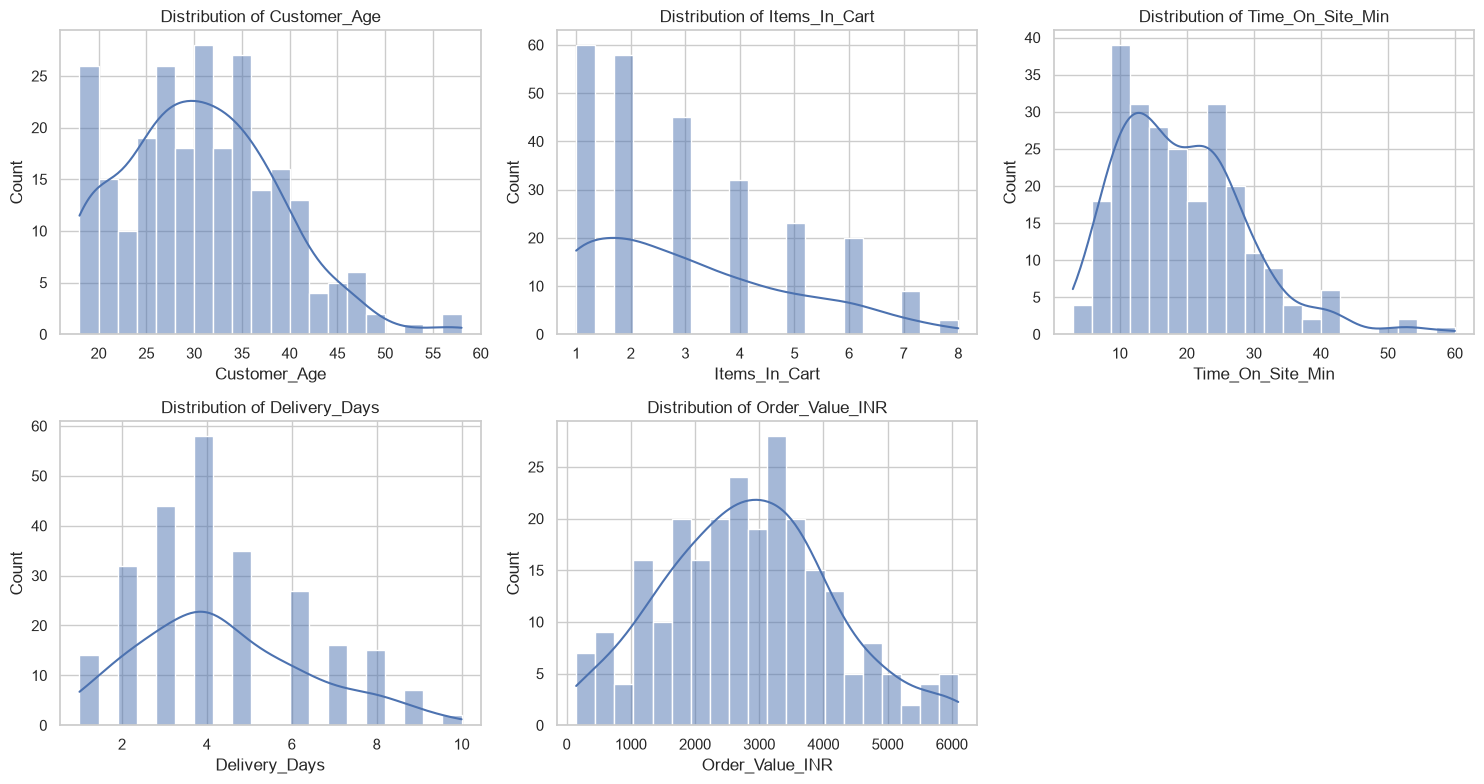

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=20)
    ax.set_title(f"Distribution of {col}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Boxplot

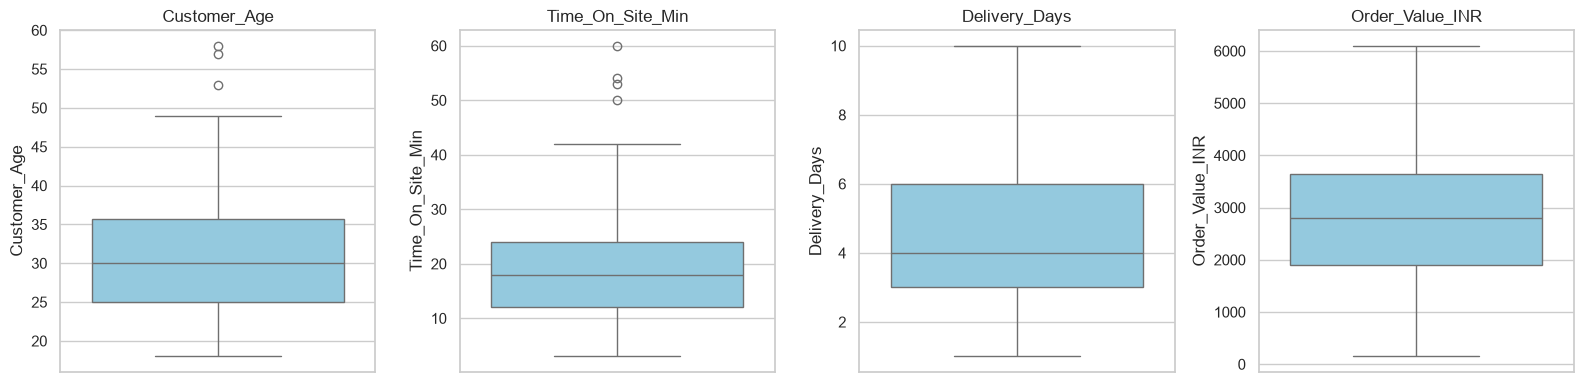

In [46]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["Customer_Age", "Time_On_Site_Min", "Delivery_Days", "Order_Value_INR"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Revenue_and_average

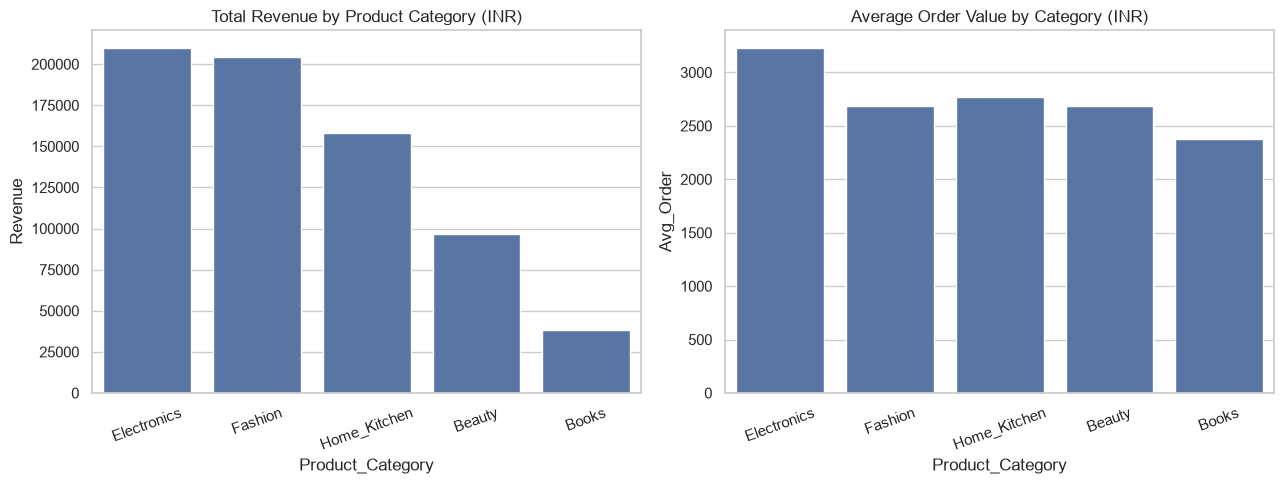

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=cat.index, y=cat["Revenue"], ax=ax[0])
ax[0].set_title("Total Revenue by Product Category (INR)")
ax[0].tick_params(axis="x", rotation=20)
sns.barplot(x=cat.index, y=cat["Avg_Order"], ax=ax[1])
ax[1].set_title("Average Order Value by Category (INR)")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

order_and_revenue_share

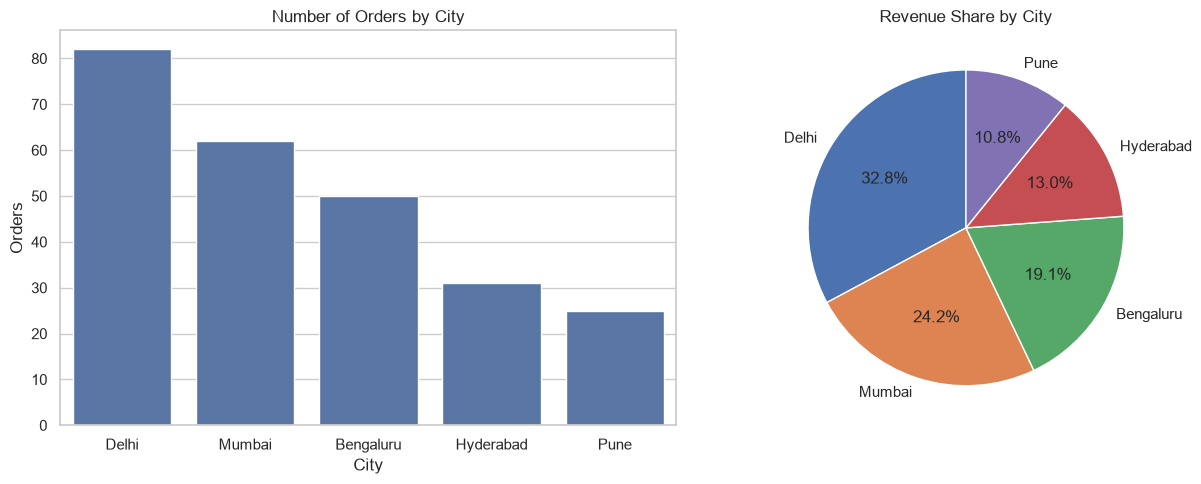

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=city.index, y=city["Orders"], ax=ax[0])
ax[0].set_title("Number of Orders by City")
ax[1].pie(city["Revenue"], labels=city.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Revenue Share by City")
plt.tight_layout()
plt.show()

payment_

payment_mode_cutomer_type

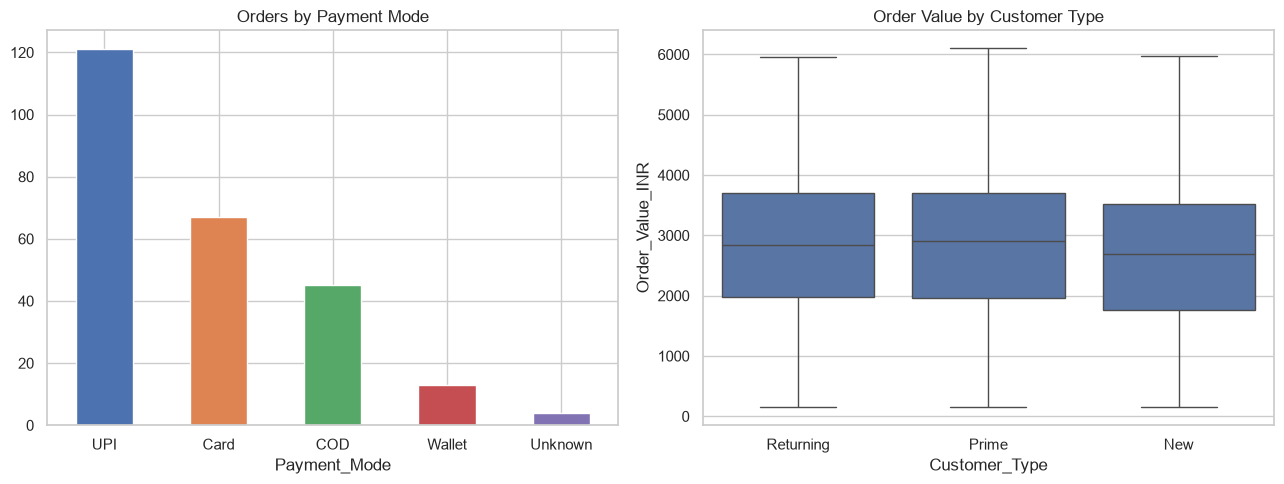

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
df["Payment_Mode"].value_counts().plot(kind="bar", ax=ax[0], color=sns.color_palette("deep"))
ax[0].set_title("Orders by Payment Mode")
ax[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df, x="Customer_Type", y="Order_Value_INR", ax=ax[1])
ax[1].set_title("Order Value by Customer Type")
plt.tight_layout()
plt.show()

productcategory

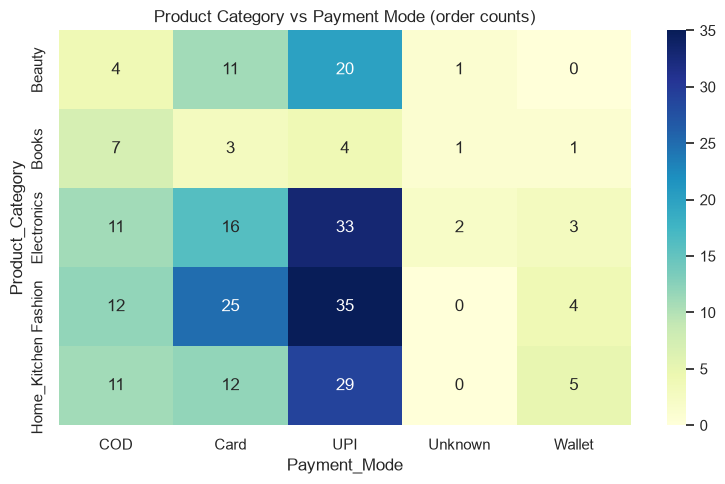

In [50]:
ct = pd.crosstab(df["Product_Category"], df["Payment_Mode"])
plt.figure(figsize=(8, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Product Category vs Payment Mode (order counts)")
plt.tight_layout()
plt.show()

monthly_Product

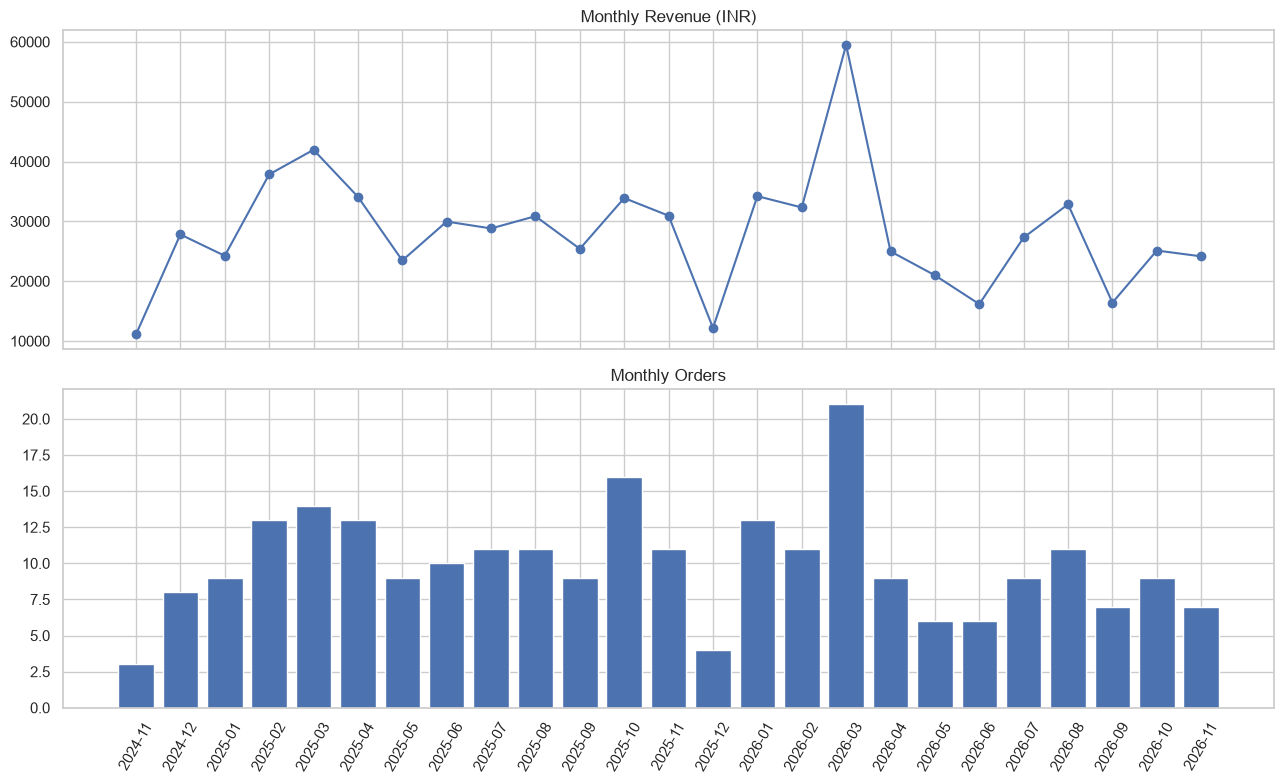

In [51]:
monthly = df.groupby("Month")["Order_Value_INR"].agg(["count", "sum"])
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax[0].plot(monthly.index, monthly["sum"], marker="o")
ax[0].set_title("Monthly Revenue (INR)")
ax[1].bar(monthly.index, monthly["count"])
ax[1].set_title("Monthly Orders")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

Correlation_Heatmap

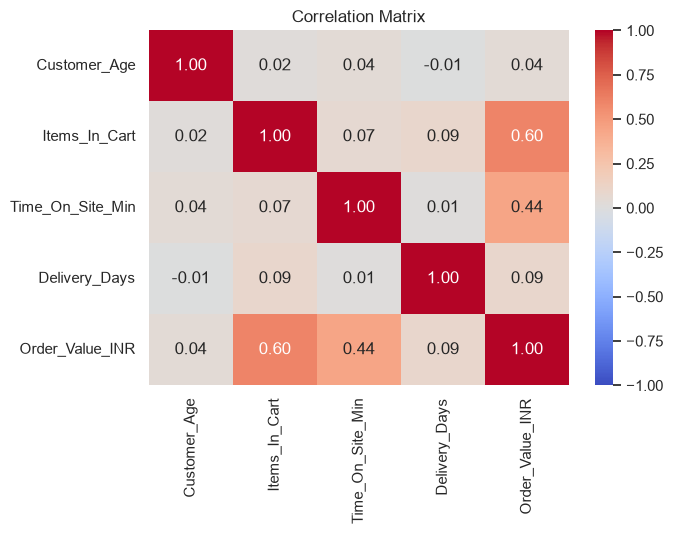

In [52]:
corr = df[num_cols].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

item_in_cart

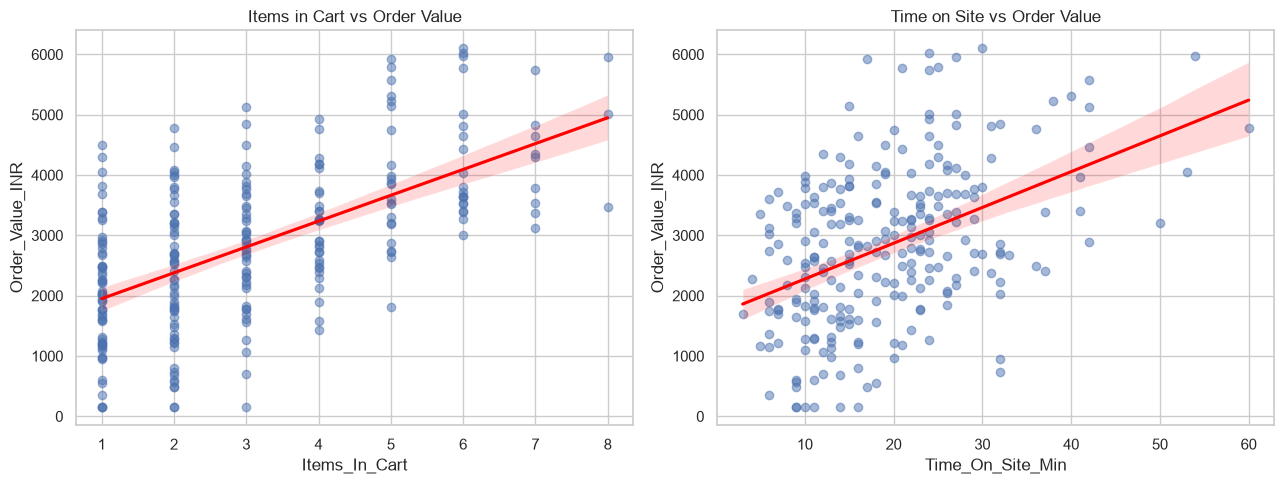

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.regplot(data=df, x="Items_In_Cart", y="Order_Value_INR", ax=ax[0],
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
ax[0].set_title("Items in Cart vs Order Value")
sns.regplot(data=df, x="Time_On_Site_Min", y="Order_Value_INR", ax=ax[1],
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
ax[1].set_title("Time on Site vs Order Value")
plt.tight_layout()
plt.show()

Delivery_days_by_city

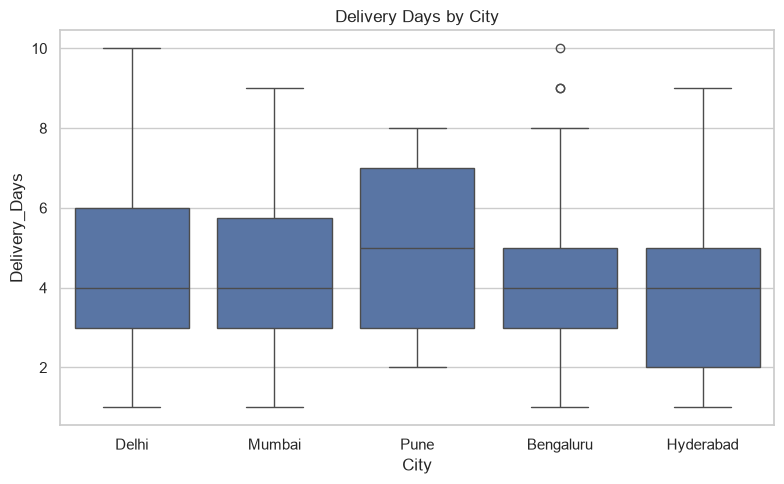

In [54]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="City", y="Delivery_Days")
plt.title("Delivery Days by City")
plt.tight_layout()
plt.show()

Order_by_Weekdays

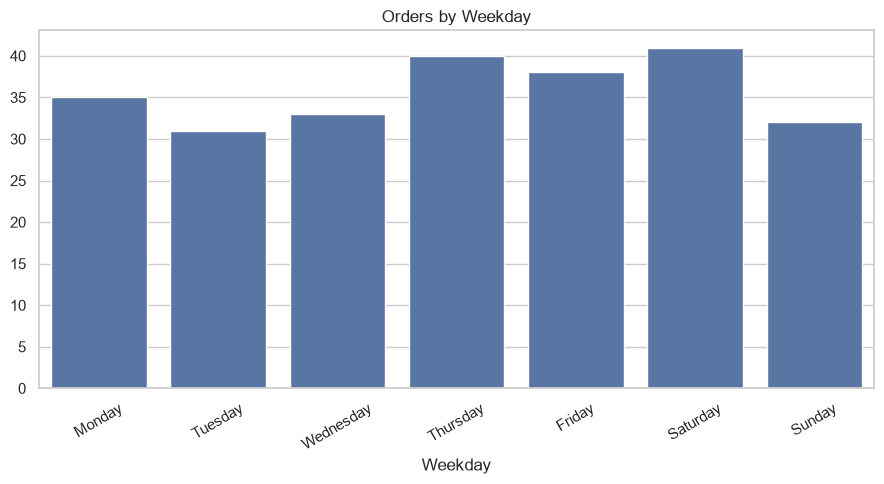

In [55]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df["Weekday"].value_counts().reindex(order)
plt.figure(figsize=(9, 5))
sns.barplot(x=wd.index, y=wd.values)
plt.title("Orders by Weekday")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

stastical_test

In [56]:
corr.round(2)

,Customer_Age,Items_In_Cart,Time_On_Site_Min,Delivery_Days,Order_Value_INR
Customer_Age,1.00,0.02,0.04,-0.01,0.04
Items_In_Cart,0.02,1.00,0.07,0.09,0.60
Time_On_Site_Min,0.04,0.07,1.00,0.01,0.44
Delivery_Days,-0.01,0.09,0.01,1.00,0.09
Order_Value_INR,0.04,0.60,0.44,0.09,1.00


person_correlation

In [57]:
r1, p1 = stats.pearsonr(df["Items_In_Cart"], df["Order_Value_INR"])
r2, p2 = stats.pearsonr(df["Time_On_Site_Min"], df["Order_Value_INR"])
print(f"Items_In_Cart vs Order_Value : r = {r1:.3f}, p = {p1:.4g}")
print(f"Time_On_Site  vs Order_Value : r = {r2:.3f}, p = {p2:.4g}")

Items_In_Cart vs Order_Value : r = 0.597, p = 1.462e-25
Time_On_Site  vs Order_Value : r = 0.440, p = 2.775e-13


ANNOVA

In [58]:
groups = [g["Order_Value_INR"].values for _, g in df.groupby("Product_Category")]
f, p = stats.f_oneway(*groups)
print(f"Category      : F = {f:.2f}, p = {p:.4f}", "-> significant" if p < 0.05 else "-> not significant")

groups = [g["Order_Value_INR"].values for _, g in df.groupby("Customer_Type")]
f, p = stats.f_oneway(*groups)
print(f"Customer type : F = {f:.2f}, p = {p:.4f}", "-> significant" if p < 0.05 else "-> not significant")

Category      : F = 2.46, p = 0.0464 -> significant
Customer type : F = 0.43, p = 0.6513 -> not significant


chi_sq

In [59]:
known = df[df["Payment_Mode"] != "Unknown"]

chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(known["Payment_Mode"], known["Customer_Type"]))
print(f"Payment_Mode vs Customer_Type : chi2 = {chi:.2f}, p = {p:.3f}", "-> related" if p < 0.05 else "-> independent")

chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(known["Product_Category"], known["Payment_Mode"]))
print(f"Category vs Payment_Mode      : chi2 = {chi:.2f}, p = {p:.3f}", "-> related" if p < 0.05 else "-> independent")

Payment_Mode vs Customer_Type : chi2 = 2.79, p = 0.835 -> independent
Category vs Payment_Mode      : chi2 = 15.67, p = 0.207 -> independent


electronics_vs_other

In [60]:
a = df.loc[df["Product_Category"] == "Electronics", "Order_Value_INR"]
b = df.loc[df["Product_Category"] != "Electronics", "Order_Value_INR"]
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"t = {t:.2f}, p = {p:.4f}", "-> significant" if p < 0.05 else "-> not significant")

t = 2.92, p = 0.0043 -> significant


simple_linear_aggresion

In [61]:
slope, intercept, r_val, p_val, se = stats.linregress(df["Items_In_Cart"], df["Order_Value_INR"])
print(f"Order_Value = {intercept:.0f} + {slope:.0f} x Items_In_Cart")
print(f"R-squared = {r_val**2:.3f}")

Order_Value = 1522 + 428 x Items_In_Cart
R-squared = 0.357


Key_Insight

In [62]:
top_cat = cat.index[0]
top_city = city.index[0]

print("Top revenue category  :", top_cat, f"({cat.loc[top_cat, 'Revenue_%']}% of revenue)")
print("Top city              :", top_city, f"({city.loc[top_city, 'Revenue_%']}% of revenue)")
print("Most used payment mode:", df["Payment_Mode"].value_counts().idxmax())
print("Largest customer group:", df["Customer_Type"].value_counts().idxmax())
print("Average delivery time :", round(df["Delivery_Days"].mean(), 1), "days")
print("Strongest driver      : items in cart (r =", round(corr.loc["Items_In_Cart", "Order_Value_INR"], 2), ")")

Top revenue category  : Electronics (29.7% of revenue)
Top city              : Delhi (32.8% of revenue)
Most used payment mode: UPI
Largest customer group: Returning
Average delivery time : 4.4 days
Strongest driver      : items in cart (r = 0.6 )
